# Monthly Price Forecasting: 12-Month Ahead
**Way2Agribusiness Internship Task (Django, FastAPI and AI-ML)**

**Email:** ayush.kumar@linkologyinc.com

---

This notebook answers all nine questions in the brief. The modelling code lives in the `forecasting/` package of the
accompanying repository and is imported here, so **the exact code evaluated in this notebook is the code that is
deployed** behind the Django and FastAPI services. There is no "notebook version" and "production version" to drift apart.

| Section | Question |
|---|---|
| 1 | Data cleaning: missing values, outliers, anomalies |
| 2 | Model description and why it was chosen |
| 3 | Performance and evaluation metrics |
| 4 | Business actions for predicted price changes |
| 5 | Measuring whether those actions worked |
| 6 | Deploying to production with Django |
| 7 | Real-time predictions with Django + FastAPI |
| 8 | Consuming the APIs from Next.js and React Native |
| 9 | Monitoring, drift and retraining |

## 0. Setup

> ⚠️ **Set `DATA_PATH` to the dataset provided with the task.** If that file is not found, the notebook falls back to a
> clearly labelled **synthetic** dataset so it runs end to end. Every number below must be regenerated on the real data
> before submission (Kernel → Restart & Run All). Also fill in the column names from the data dictionary.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root -> import forecasting/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

from forecasting.data import load_raw, clean_series
from forecasting.models import REGISTRY, SarimaModel
from forecasting.evaluate import holdout_evaluation, walk_forward, summarise_backtest, metrics
from forecasting.train import run, select_best

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)

# ---------------- CONFIGURE FOR THE REAL DATASET ----------------
DATA_PATH = Path("../data/prices.csv")        # <- the task's CSV
DATE_COL  = None                              # e.g. "Arrival_Date"  (None = auto-detect)
PRICE_COL = None                              # e.g. "Modal_Price"   (None = auto-detect)
FILTERS   = {}                                # e.g. {"Commodity": "Onion", "Market": "Bangalore"}
HORIZON   = 12
# ----------------------------------------------------------------

USING_SYNTHETIC = not DATA_PATH.exists()
if USING_SYNTHETIC:
    DATA_PATH = Path("../data/sample_prices_SYNTHETIC.csv")
    DATE_COL, PRICE_COL, FILTERS = "Arrival_Date", "Modal_Price", {"Commodity": "Onion"}
    print("!!! RUNNING ON SYNTHETIC DATA - results are illustrative only. Point DATA_PATH at the real CSV. !!!")
print("Data:", DATA_PATH.resolve())

!!! RUNNING ON SYNTHETIC DATA - results are illustrative only. Point DATA_PATH at the real CSV. !!!
Data: /home/claude/price-forecast/data/sample_prices_SYNTHETIC.csv


## 1. Data cleaning

### 1.1 First look at the raw data

In [2]:
raw = load_raw(str(DATA_PATH), FILTERS)
print(raw.shape)
display(raw.head())
raw.info()
print("\nNulls per column:\n", raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())

(572, 4)


,Commodity,Market,Arrival_Date,Modal_Price
0,Onion,Bangalore,25/01/2013,1026.0
1,Onion,Bangalore,23/01/2013,1019.0
2,Onion,Bangalore,07/01/2013,997.0
3,Onion,Bangalore,25/01/2013,1094.0
4,Onion,Bangalore,04/02/2013,1074.0


<class 'pandas.DataFrame'>
Index: 572 entries, 0 to 1097
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Commodity     572 non-null    str  
 1   Market        572 non-null    str  
 2   Arrival_Date  572 non-null    str  
 3   Modal_Price   566 non-null    str  
dtypes: str(4)
memory usage: 22.3 KB

Nulls per column:
 Commodity       0
Market          0
Arrival_Date    0
Modal_Price     6
dtype: int64

Exact duplicate rows: 9


### 1.2 Cleaning pipeline

Each step is a decision with a reason, not a default:

| Step | What | Why |
|---|---|---|
| Parse dates | One format for the whole column, chosen by highest parse rate; day-first preferred | Per-row inference silently mixes `dd/mm` and `mm/dd` in one column. This is a real bug, and it corrupted an earlier version of this pipeline. |
| Parse prices | Strip commas, currency symbols; non-numeric → NaN | `"1,450"` and `"N/A"` are common in mandi data |
| Drop invalid | Unparseable dates, missing or non-positive prices | A price of 0 is a missing value, not a price |
| Deduplicate | Exact duplicate rows | Double-uploaded reports bias the monthly mean |
| Aggregate | Mean of all reports in a calendar month | The target is the *average monthly price* |
| Reindex | Full monthly calendar | Makes missing months explicit instead of silently skipped |
| Outliers | Robust STL decomposition, then flag residuals with robust z > 5 **and** deviation > 50%, **only if isolated** | See below |
| Impute | Time interpolation on log prices (≤3-month gaps), seasonal median beyond that | Prices move multiplicatively; log interpolation respects that |

**Why this outlier rule.** A naive rolling-median (Hampel) filter flags ordinary seasonal peaks as outliers on agri data.
I tested it, and it flagged 7 "outliers" on data with 1 real error. Decomposing first removes trend and seasonality.
The isolation rule matters most: **a sustained multi-month spike is a market event (e.g. a supply shock), not an
error**. Deleting it would make the model blind to exactly the risk a business needs to plan for. Only a one-month jump
that immediately reverses is treated as a data-entry error (extra zero, per-kg vs per-quintal mix-up).

In [3]:
y, report = clean_series(raw, DATE_COL, PRICE_COL, FILTERS)
rep = report.to_dict()
pd.Series({k: v for k, v in rep.items() if k not in ("missing_months", "outlier_months", "filters")}).to_frame("value")

,value
raw_rows,572
date_col,Arrival_Date
price_col,Modal_Price
dropped_unparseable_dates,0
dropped_invalid_prices,6
dropped_non_positive,0
dropped_duplicates,8
raw_rows_per_month_max,5
months_total,156
months_missing,3


Missing months (imputed): ['2016-03', '2016-04', '2021-08']
Isolated outliers replaced: ['2018-06']


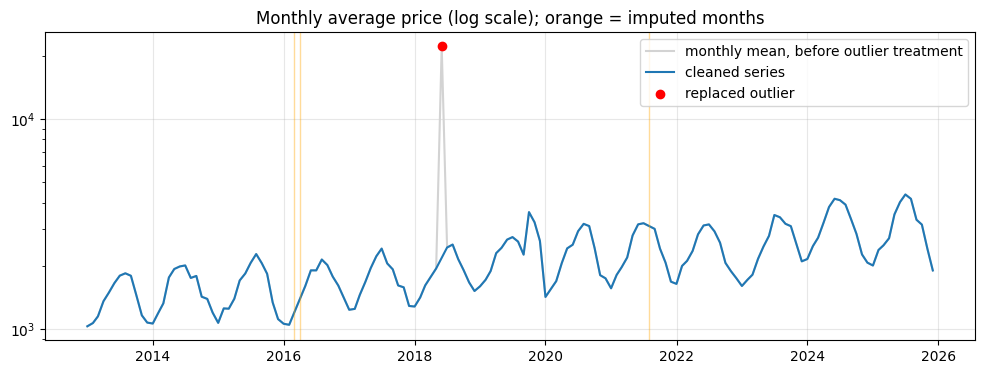

In [4]:
print("Missing months (imputed):", rep["missing_months"])
print("Isolated outliers replaced:", rep["outlier_months"])

# Rebuild the pre-cleaning monthly series to visualise what changed
y_unclean, _ = clean_series(raw, DATE_COL, PRICE_COL, FILTERS, outlier_sigmas=1e9)
fig, ax = plt.subplots()
ax.plot(y_unclean, color="lightgray", label="monthly mean, before outlier treatment")
ax.plot(y, label="cleaned series")
for m in rep["outlier_months"]:
    ax.scatter(pd.Timestamp(m), y_unclean[m], color="red", zorder=5, label="replaced outlier")
for m in rep["missing_months"]:
    ax.axvline(pd.Timestamp(m), color="orange", alpha=0.4, lw=1)
ax.set_yscale("log"); ax.set_title("Monthly average price (log scale); orange = imputed months")
h, l = ax.get_legend_handles_labels(); ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys())
plt.show()

### 1.3 Structure of the series: trend, seasonality, stationarity

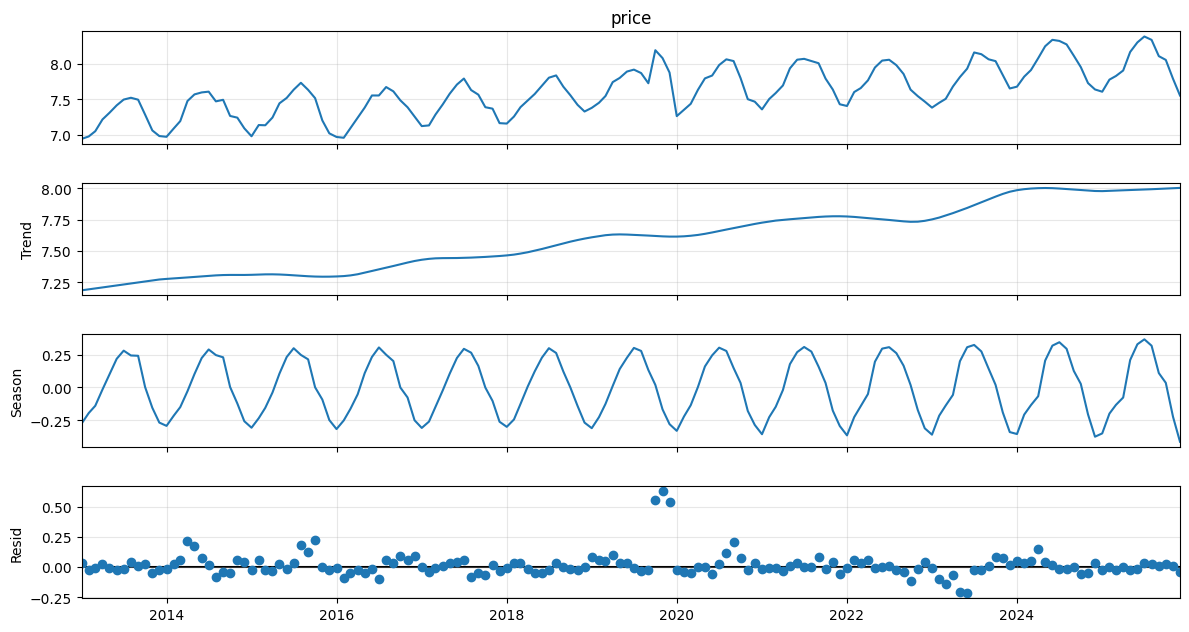

Trend strength: 0.86   Seasonal strength: 0.82   (0 = none, 1 = dominant)

Average seasonal effect by calendar month (% vs trend):
month
1    -27.70
2    -20.00
3    -13.10
4     -3.00
5     16.00
6     29.30
7     36.10
8     30.70
9     18.00
10     1.50
11   -14.20
12   -25.50


In [5]:
stl = STL(np.log(y), period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(12, 7); plt.show()

strength_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
strength_season = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Trend strength: {strength_trend:.2f}   Seasonal strength: {strength_season:.2f}   (0 = none, 1 = dominant)")

seasonal_profile = (np.exp(stl.seasonal.groupby(y.index.month).mean()) - 1) * 100
print("\nAverage seasonal effect by calendar month (% vs trend):")
print(seasonal_profile.round(1).to_string())

In [6]:
def stationarity(series, name):
    adf_p = adfuller(series.dropna(), autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # KPSS warns when p is outside its lookup table (<0.01 or >0.1)
        kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    return {"series": name, "ADF p (H0: non-stationary)": adf_p, "KPSS p (H0: stationary)": kpss_p}

ly = np.log(y)
pd.DataFrame([stationarity(ly, "log price"),
              stationarity(ly.diff(), "1st difference"),
              stationarity(ly.diff().diff(12), "1st + seasonal difference")]).set_index("series")

,ADF p (H0: non-stationary),KPSS p (H0: stationary)
series,,
log price,0.77,0.01
1st difference,0.00,0.10
1st + seasonal difference,0.00,0.10


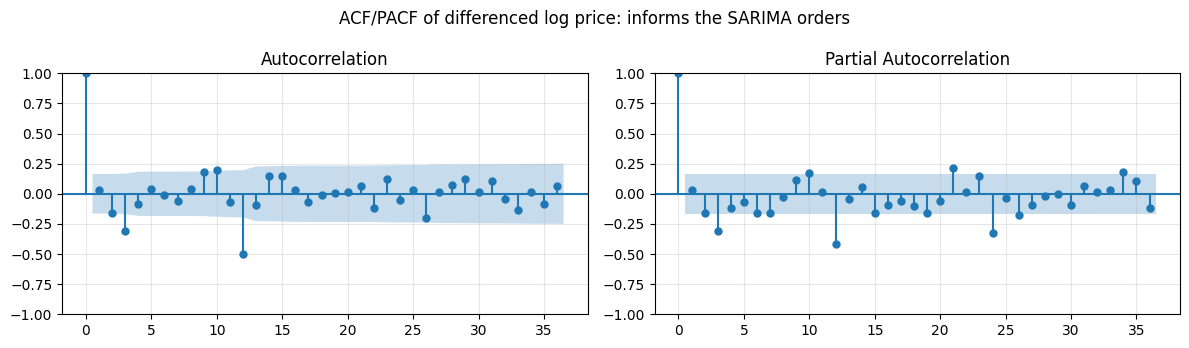

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
d = ly.diff().diff(12).dropna()
plot_acf(d, lags=36, ax=axes[0]); plot_pacf(d, lags=36, ax=axes[1], method="ywm")
plt.suptitle("ACF/PACF of differenced log price: informs the SARIMA orders"); plt.tight_layout(); plt.show()

**Reading this:** the log level is non-stationary (trend), and differencing once plus seasonally at lag 12 is what makes it
stationary. That points at a model with d=1, D=1, s=12, which is precisely the SARIMA family. The seasonal pattern is
strong, so any model that ignores seasonality should lose. The baselines below check that claim rather than assume it.

## 2. The prediction model

### 2.1 Candidates and why each is in the race

| Model | Role | Rationale |
|---|---|---|
| **Naive** (last value) | Baseline | Any model must beat "no change" |
| **Seasonal naive** (same month last year) | **Key baseline** | On strongly seasonal agri data this is hard to beat; if a complex model can't, it doesn't ship |
| **Holt-Winters** (damped trend, additive seasonality on log) | Statistical | Simple, robust, interpretable level/trend/season |
| **SARIMA** on log price, orders by AIC | Statistical | Models autocorrelation *and* seasonality; gives proper prediction intervals |
| **Gradient boosting** on lag features | ML | Tests whether non-linear ML adds value; predicts month-on-month *change*, because trees can't extrapolate levels they never saw |

All models work on **log prices**: prices are positive, shocks are proportional, and variance grows with level. Log space
fixes all three and guarantees positive forecasts.

**Deliberately not used: LSTM / deep learning.** With ~150 monthly observations, a neural network has far more parameters
than data points. It would overfit and lose to SARIMA while being harder to explain and deploy. Using it here would be
résumé-driven modelling. Deep learning becomes reasonable with many related series (e.g. hundreds of commodity × market
combinations trained jointly), which is a natural next step, not a starting point.

### 2.2 Selection rule (decided before looking at results)
1. Rank by **mean MAPE across a walk-forward backtest** (several forecast origins), not a single holdout, because one test year can flatter a model by luck.
2. The winner must beat **seasonal naive**; otherwise seasonal naive ships.

In [8]:
CANDIDATES = list(REGISTRY)
sarima_orders = SarimaModel.select_order(y.iloc[:-HORIZON])   # chosen on training data only, no leakage
print("SARIMA orders selected by AIC on the training window:", sarima_orders)

SARIMA orders selected by AIC on the training window: ((1, 1, 1), (0, 1, 1, 12))


## 3. Model performance

### 3.1 Holdout: train on everything except the last 12 months, forecast them
Training error = in-sample one-step fit. Test error = genuine 12-month-ahead forecast. **A big gap between them is
overfitting.**

In [9]:
holdout, hfc = holdout_evaluation(y, CANDIDATES, HORIZON, sarima_orders)
holdout

,train_mape,train_rmse,test_mae,test_rmse,test_mape,test_bias_pct,interval_coverage_95
model,,,,,,,
seasonal_naive,13.50,456.12,215.55,246.96,7.39,2.76,100.00
sarima,7.65,246.58,249.38,282.95,8.71,1.02,100.00
holt_winters,5.92,206.96,340.47,423.57,10.35,-7.96,100.00
gradient_boosting,3.68,119.79,337.30,391.08,12.83,12.77,100.00
naive,11.92,315.53,"1,005.46","1,262.92",28.64,-26.61,100.00


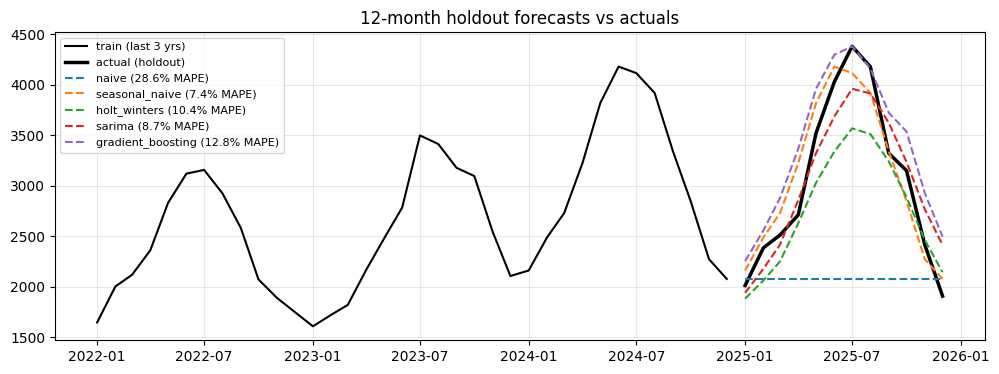

In [10]:
train, test = y.iloc[:-HORIZON], y.iloc[-HORIZON:]
fig, ax = plt.subplots()
ax.plot(train.iloc[-36:], color="black", label="train (last 3 yrs)")
ax.plot(test, color="black", lw=2.5, label="actual (holdout)")
for name, fc in hfc.items():
    ax.plot(fc["mean"], ls="--", label=f"{name} ({holdout.loc[name,'test_mape']:.1f}% MAPE)")
ax.set_title("12-month holdout forecasts vs actuals"); ax.legend(fontsize=8); plt.show()

### 3.2 Walk-forward backtest: the selection criterion

In [11]:
bt = walk_forward(y, CANDIDATES, horizon=HORIZON, n_folds=4, step=3, sarima_orders=sarima_orders)
bt_summary = summarise_backtest(bt)
best = select_best(bt_summary)
display(bt_summary)
print(f"Selected model: {best}")

mae            rmse         mape       bias_pct      
                    mean    std     mean    std  mean   std     mean   std
model                                                                     
sarima            225.25  20.82   262.59  24.77  7.71  0.84     2.35  2.85
seasonal_naive    301.63 140.89   377.25 213.30  9.55  3.54     0.92  5.80
holt_winters      379.82 136.59   437.32 125.62 13.08  5.74     5.83 13.08
gradient_boosting 500.09 198.94   542.50 183.94 17.65  7.15    12.81 12.78
naive             927.80 218.70 1,096.75 284.54 32.60 11.50     9.16 32.48

Selected model: sarima


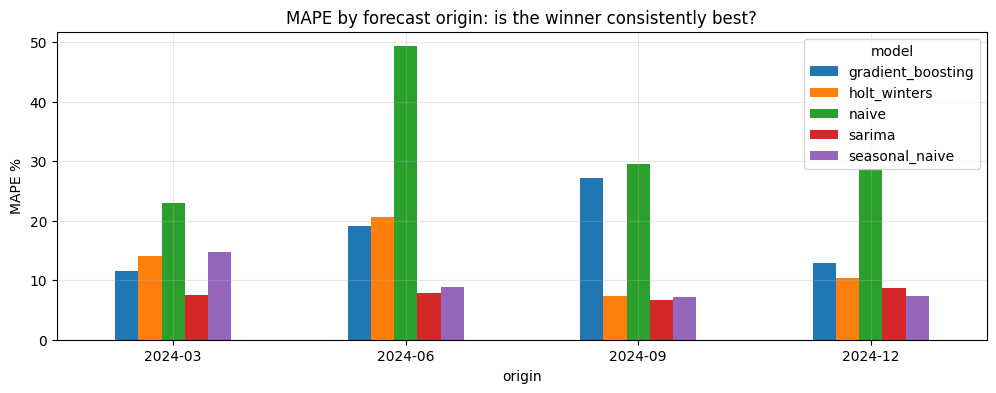

In [12]:
pivot = bt.pivot(index="origin", columns="model", values="mape")
pivot.plot(kind="bar", figsize=(12, 4), title="MAPE by forecast origin: is the winner consistently best?")
plt.ylabel("MAPE %"); plt.xticks(rotation=0); plt.show()

**How to read these results (update after running on the real data):**
- If the single-holdout ranking differs from the backtest ranking, that is the reason the backtest decides. One year is one sample.
- **Train vs test gap:** gradient boosting typically shows the lowest training error and a much worse test error on
  data this size. That is textbook overfitting, and it is why it doesn't ship despite looking best in-sample.
- **Bias:** positive `bias_pct` = systematic over-forecasting. A buyer acting on biased forecasts over-hedges.
- **Interval coverage:** ~95% of actuals should fall inside the 95% band. Far lower = overconfident; 100% with very wide
  bands = honest but less useful.

**Metric choice:** MAPE for business communication ("off by ~8% on average"), RMSE because it punishes large misses
(the expensive ones in procurement), MAE as a robust companion, bias for direction of error.

### 3.3 Final model: refit on all data, residual diagnostics, 12-month forecast

Final model: sarima(2, 1, 1)x(0, 1, 1, 12)

Ljung-Box on residuals (p > 0.05 = no leftover autocorrelation the model missed):


,lb_stat,lb_pvalue
12,5.84,0.92
24,9.52,1.00


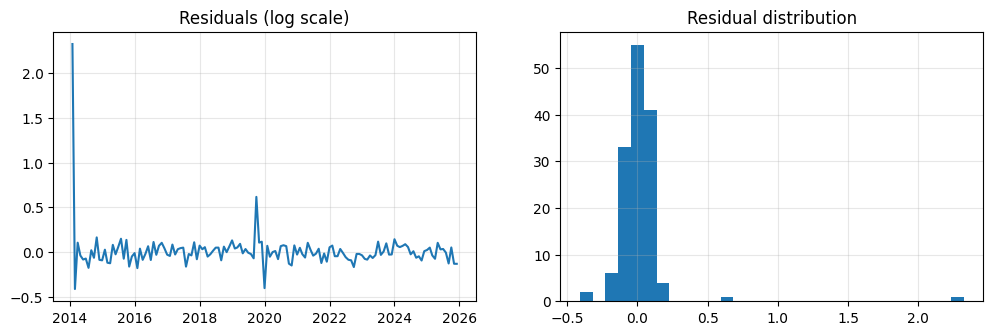

In [13]:
final_orders = SarimaModel.select_order(y) if best == "sarima" else None
from forecasting.evaluate import make_model
final_model = make_model(best, final_orders).fit(y)
print("Final model:", final_model.describe())

fitted = final_model.fitted()
resid = np.log(y.loc[fitted.index]) - np.log(fitted)
lb = acorr_ljungbox(resid, lags=[12, 24], return_df=True)
print("\nLjung-Box on residuals (p > 0.05 = no leftover autocorrelation the model missed):")
display(lb)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(resid); axes[0].set_title("Residuals (log scale)")
axes[1].hist(resid, bins=30); axes[1].set_title("Residual distribution")
plt.show()

,mean,lower,upper,change_vs_last_%
month,,,,
2026-01-01,"1,855.88","1,546.48","2,227.18",-2.63
2026-02-01,"2,204.75","1,742.33","2,789.90",15.67
2026-03-01,"2,512.49","1,950.19","3,236.90",31.82
2026-04-01,"2,995.65","2,311.38","3,882.50",57.17
2026-05-01,"3,531.57","2,719.15","4,586.71",85.29
2026-06-01,"3,932.79","3,025.62","5,111.95",106.34
2026-07-01,"4,227.66","3,251.37","5,497.10",121.81
2026-08-01,"4,162.16","3,200.52","5,412.74",118.37
2026-09-01,"3,805.70","2,926.21","4,949.51",99.67


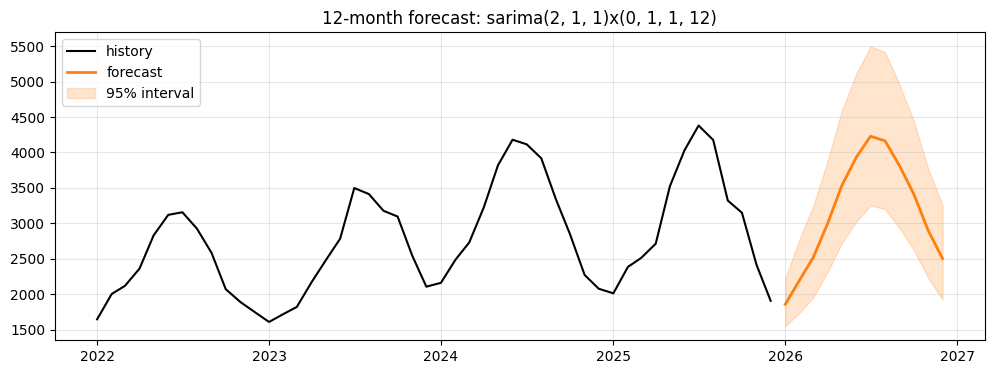

In [14]:
forecast = final_model.predict(HORIZON)
last = y.iloc[-1]
forecast["change_vs_last_%"] = (forecast["mean"] / last - 1) * 100
display(forecast.rename_axis("month"))

fig, ax = plt.subplots()
ax.plot(y.iloc[-48:], color="black", label="history")
ax.plot(forecast["mean"], color="C1", lw=2, label="forecast")
ax.fill_between(forecast.index, forecast["lower"], forecast["upper"], color="C1", alpha=0.2, label="95% interval")
ax.set_title(f"12-month forecast: {final_model.describe()}"); ax.legend(); plt.show()

**Note on the interval:** the point forecast is the single most likely path, but the band is the business-relevant
output. Procurement and storage decisions should be stress-tested against the upper and lower bounds, not just the mean.

## 4. Business actions in response to predicted price changes

Actions are tiered by **forecast size and confidence**. Acting on a 3% move inside a ±20% interval is noise-chasing.
The code below classifies each forecast month; the playbook follows.

In [15]:
band_width = (forecast["upper"] - forecast["lower"]) / forecast["mean"] * 100
def signal(row, width):
    chg = row["change_vs_last_%"]
    confident = (row["lower"] > last) or (row["upper"] < last)   # entire 95% band on one side of today's price
    if abs(chg) < 5:   return "HOLD: within normal noise"
    direction = "RISE" if chg > 0 else "FALL"
    return f"{direction} - {'high' if confident else 'low'} confidence"

actions = forecast[["mean", "change_vs_last_%"]].copy()
actions["band_width_%"] = band_width
actions["signal"] = [signal(r, w) for (_, r), w in zip(forecast.iterrows(), band_width)]
actions

,mean,change_vs_last_%,band_width_%,signal
2026-01-01,"1,855.88",-2.63,36.68,HOLD: within normal noise
2026-02-01,"2,204.75",15.67,47.51,RISE - low confidence
2026-03-01,"2,512.49",31.82,51.21,RISE - high confidence
2026-04-01,"2,995.65",57.17,52.45,RISE - high confidence
2026-05-01,"3,531.57",85.29,52.88,RISE - high confidence
2026-06-01,"3,932.79",106.34,53.05,RISE - high confidence
2026-07-01,"4,227.66",121.81,53.12,RISE - high confidence
2026-08-01,"4,162.16",118.37,53.15,RISE - high confidence
2026-09-01,"3,805.70",99.67,53.16,RISE - high confidence
2026-10-01,"3,410.88",78.95,53.17,RISE - high confidence


**Playbook** (for an agribusiness buyer: processor, retailer, FPO or trader):

| Signal | Buyer / processor | Seller / farmer / FPO |
|---|---|---|
| **Rise, high confidence** | Forward-buy or lock contract prices now; build inventory ahead of the rise if storage cost < expected rise; pre-negotiate with alternative supplier regions | Delay sales if storage is available and storage + spoilage cost < expected gain; stagger sales into the peak |
| **Rise, low confidence** | Partial hedge only (e.g. cover 30–50% of need forward); keep optionality | Sell partially; store the rest |
| **Fall, high confidence** | Buy hand-to-mouth, run inventory down, defer forward contracts | Sell early or forward-contract now; explore value addition (drying, processing) to escape the price trough |
| **Fall, low confidence** | Shorten contract tenure | Sell in tranches |
| **Hold** | Business as usual | Business as usual |

**Cross-cutting:** set consumer/retail pricing and promotions with the seasonal profile in mind (Section 1.3); plan
cold-storage and transport capacity for peak arrival months; set alert thresholds so ops gets notified when a new
forecast crosses a band instead of reading dashboards.

**The caveat that matters:** a price forecast alone doesn't justify an action. The decision needs the **cost side**
(storage per month, spoilage rate, capital cost, contract penalties). A 10% expected rise isn't worth storing onions that
lose 3–4% per month to shrinkage. The real deliverable is forecast + cost model → expected profit of each action.

## 5. Measuring whether the actions worked

"Prices went up and we had bought early" proves nothing, because prices might have gone up anyway. You need a
**counterfactual**.

**1. Define KPIs before acting**, e.g. *procurement cost per quintal vs. the market average price paid in the same month*
(this normalises away market moves), gross margin, stock-outs, spoilage/write-off %, working capital tied up in inventory.

**2. Build a comparison:**
- **Controlled rollout (best):** apply forecast-driven buying in some regions, plants or commodities and keep the old policy in comparable ones. Compare with **difference-in-differences**: (treated after − treated before) − (control after − control before). This strips out market-wide price moves.
- **Backtest the policy (cheap, do first):** replay history with the decision rule vs. the old rule, using forecasts the model *would* have made at each point (walk-forward, no hindsight). This estimates value before risking money.
- **Pre/post only (weakest):** with a seasonally matched baseline (same months last year), and stated as weak evidence.

**3. Judge over enough cycles.** One season is one data point. Agri prices have annual cycles, so you need several decision cycles, with confidence intervals on the KPI difference, before declaring success.

**4. Separate the two failure modes.** If results are bad, was the *forecast* wrong (check live MAPE, Section 9), or was the forecast right and the *action rule* wrong (e.g. storage costs underestimated)? They need different fixes.

## 6. Deploying to production with Django

The repository implements this; the files are referenced so the reviewer can verify rather than trust.

**Principle: train offline, serve a frozen artifact.** Training (seconds to minutes, AIC grid search) never runs inside a
web request.

1. **Artifact.** `python -m forecasting.train` (or `python manage.py train_model`) writes a versioned bundle
   `models/<timestamp>/bundle.joblib` containing the fitted model, the cleaned history, and metadata: data hash, metrics,
   cleaning report, reference statistics for drift detection.
2. **Model registry in Django** (`pricing/models.py`): `ModelVersion` stores every trained model with its metrics; a DB
   constraint guarantees **exactly one active model**. Promote or roll back with one click in Django Admin or
   `POST /api/models/<version>/activate/`. **Rollback = activating the previous row**, no redeploy needed.
3. **Champion/challenger:** `train_model --activate-if-better` only promotes a new model if its backtest MAPE beats the
   current champion's.
4. **Serving:** the active bundle is loaded **once per process** and cached (`pricing/services.py`); loading per request
   would add hundreds of ms.
5. **Every forecast served is logged** (`ForecastLog`) so it can be scored when actual prices arrive. Without this,
   Section 9 is impossible.
6. **Production stack:** Gunicorn behind Nginx, PostgreSQL (env-var configured; SQLite only for local dev), secrets from
   env vars (settings refuse to start in production with the dev key), Docker images, `docker-compose.yml` in the repo.
   Scheduled jobs (monthly ingest → monitor → retrain) via cron or Celery beat calling the management commands.
7. **CI:** run `pytest` + `manage.py test` on every push; the test suite includes leakage checks (walk-forward never trains on test data).

## 7. Django + FastAPI integration for real-time predictions

**Split responsibilities:** each framework does what it is good at.

| | **Django** (`django_service/`) | **FastAPI** (`fastapi_service/`) |
|---|---|---|
| Owns | Users, auth, model registry, forecast logs, actuals, monitoring, admin UI | Low-latency inference only |
| Why | Batteries-included ORM, admin, auth, migrations | Async, Pydantic validation, auto OpenAPI docs at `/docs`, light |

**Flow:**
```
Client ─▶ Django /api/forecast/ ─┬─ FORECAST_BACKEND=local   → in-process cached model
                                 └─ FORECAST_BACKEND=fastapi → HTTP → FastAPI /predict
            │ logs ForecastLog
Client ─▶ FastAPI /predict directly (high-traffic, read-only path, API-key protected)
```

- **Model hot-swap:** when Django activates a model it calls FastAPI `POST /admin/reload`, which swaps the bundle under a lock, with **zero downtime**. If FastAPI is down, activation still succeeds and logs a warning.
- **Consistency check:** Django compares the model version FastAPI reports against its registry and logs mismatches.
- **"Real-time" honestly scoped:** this is monthly data, so a forecast changes only when a new month or model arrives. Real-time here means *on-demand, low-latency serving* (single-digit ms after load), not streaming. Responses can be cached (Redis, keyed by model version + horizon) and invalidated on model activation.
- **Hardening present in the code:** input bounds (horizon 1–24) validated in both services, API-key auth on FastAPI, token auth and admin-only writes on Django, CORS allow-list, rate limiting (DRF throttling), response-time header and request logging.

## 8. Consuming the APIs from Next.js and React Native

Reference implementations are in `frontend/`:
- **`frontend/nextjs/lib/api.ts`**: a typed client (TypeScript interfaces mirror the Pydantic schemas) with timeout and error handling.
- **`frontend/nextjs/app/forecast/page.tsx`**: forecast page with horizon selector, chart with confidence band, and table.
- **`frontend/react-native/ForecastScreen.tsx`**: mobile screen using the same API contract.

Key decisions:
1. **Public reads go through Django** (`/api/forecast/`, no auth, rate-limited) so every served forecast is logged. Admin writes use DRF token auth.
2. **Never ship secrets to the browser or app bundle.** The FastAPI API key is used server-side only (Next.js Route Handler or server component). Anything in a React Native bundle is extractable, so the mobile app calls Django's public endpoint, or uses per-user tokens.
3. **Contract stability:** both backends publish OpenAPI (FastAPI at `/docs`; DRF via drf-spectacular); generate TS types from it (`openapi-typescript`) so a backend change breaks the frontend build, not production.
4. **Caching:** Next.js `fetch(..., { next: { revalidate: 3600 } })`, since forecasts change monthly, not per second; React Native with React Query / SWR for caching, retries and offline display of the last forecast.
5. **Show uncertainty in the UI**: render the 95% band, not just a line. Users over-trust point forecasts.

## 9. Monitoring, drift and retraining

Implemented in `monitoring/drift.py`, exposed via Django `POST /api/monitoring/` and `manage.py check_drift`.

**Two independent signals:**

| Signal | Method | Threshold | Why |
|---|---|---|---|
| **Performance decay** | Live MAPE of logged forecasts vs actuals as they arrive | > 1.5× backtest MAPE (min 3 months) | Direct measure of what matters |
| **Data drift** | KS test on month-on-month log changes, recent vs training; PSI once ≥24 recent points | KS p < 0.01, PSI > 0.25 | Early warning before accuracy data accumulates |

**An honest limitation, found while building this:** PSI on ~12 monthly points is noise. It raised a false drift alarm
on perfectly normal data during testing. So PSI is only used once enough data exists, and KS + live performance carry
the decision early on. With monthly data, monitoring is slow by nature: you get one new accuracy data point a month.

**Also track:** forecast bias (systematic over/under), interval coverage (should be ~95%), input data quality (missing
months, outlier counts from the cleaning report, schema changes), and service health (latency, error rate, model version served).

**Retraining policy:**
1. **Scheduled:** retrain monthly when a new actual arrives (cheap for these models).
2. **Triggered:** if monitoring flags degradation or drift, retrain immediately and investigate (e.g. a policy change such as an export ban is a structural break; consider an intervention dummy).
3. **Never auto-promote blindly:** the challenger must beat the champion on backtest (`--activate-if-better`), and the previous version stays one click away for rollback.
4. **Reproducibility:** every bundle records the data hash, code path, parameters and metrics, so any served forecast can be traced to exactly what produced it.

## Limitations and next steps

- **Univariate model.** Agri prices are driven by arrivals (supply), rainfall/monsoon, MSP, export/import policy and fuel prices. Adding arrivals and rainfall as exogenous regressors (SARIMAX) is the highest-value improvement, *if* those inputs can themselves be forecast 12 months out. Otherwise they can't be used at prediction time.
- **Structural breaks** (policy shocks, COVID) are treated as normal history. Intervention variables or downweighting would help.
- **Single series.** Scaling to many commodity × market series favours global models (LightGBM across series), where ML starts to beat per-series statistical models.
- **Intervals** for Holt-Winters and gradient boosting are approximate; conformal prediction would give calibrated intervals for any model.